# Practice 07 — DL Training Pipeline

**Goal:** build the mini-batch training pipeline once, then reuse it to compare two models.

| Stage | What it produces |
|:---|:---|
| Data | train / validation / test split, standardized, wrapped in `DataLoader` |
| Model | an `nn.Module` subclass returning logits |
| Loss + optimizer | `nn.CrossEntropyLoss`, `torch.optim.Adam` |
| `train` / `evaluate` | the epoch loop and the no-grad evaluation, written once |
| Diagnostics | learning curves, final test score, confusion matrix |

- Steps 0–7 → the pipeline; Steps 8–11 → a plain MLP vs. the same MLP with four added techniques
- Data → `load_digits`: 1797 digits, $8 \times 8$ pixels flattened to 64 features, labels 0–9

---
## Step 0. Imports and Setup

In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import TensorDataset, DataLoader

np.random.seed(42)
torch.manual_seed(42)

plt.rcParams['axes.unicode_minus'] = False   # plain '-' for negative tick labels

# the model and each batch are moved to this device (inside train / evaluate); on a CPU-only machine .to(device) is a no-op
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

device: cpu


---
## Step 1. Data — Split, Then Standardize

| Set | When it is read | Role |
|:---|:---|:---|
| Train (60%) | every batch | updates the weights |
| Validation (20%) | once per epoch | monitors generalization |
| Test (20%) | never | scored once, at the end |

In [2]:
digits = load_digits()
X = digits.data                 # (1797, 64) pixel intensities, 0-16
y = digits.target               # (1797,) labels 0-9

print(f'X: {X.shape}, y: {y.shape}, classes: {np.unique(y)}')

X: (1797, 64), y: (1797,), classes: [0 1 2 3 4 5 6 7 8 9]


- One sample → an 8 × 8 image; flattened, its 64 pixel values are the 64 features = one row of `X`

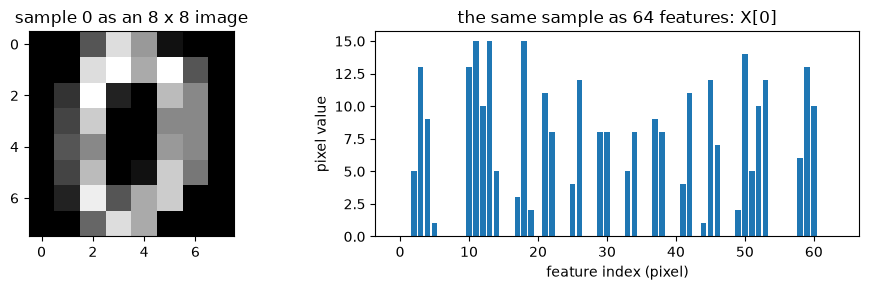

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

axes[0].imshow(X[0].reshape(8, 8), cmap='gray')
axes[0].set_title('sample 0 as an 8 x 8 image')
axes[1].bar(range(64), X[0])
axes[1].set_title('the same sample as 64 features: X[0]')
axes[1].set_xlabel('feature index (pixel)')
axes[1].set_ylabel('pixel value')

plt.tight_layout()
plt.show()

In [4]:
display(pd.DataFrame(X, columns=[f'pixel_{i}' for i in range(X.shape[1])]).head(10))

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_54,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,5.0,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,9.0,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0
5,0.0,0.0,12.0,10.0,0.0,0.0,0.0,0.0,0.0,0.0,...,4.0,0.0,0.0,0.0,9.0,16.0,16.0,10.0,0.0,0.0
6,0.0,0.0,0.0,12.0,13.0,0.0,0.0,0.0,0.0,0.0,...,8.0,0.0,0.0,0.0,1.0,9.0,15.0,11.0,3.0,0.0
7,0.0,0.0,7.0,8.0,13.0,16.0,15.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,13.0,5.0,0.0,0.0,0.0,0.0
8,0.0,0.0,9.0,14.0,8.0,1.0,0.0,0.0,0.0,0.0,...,8.0,0.0,0.0,0.0,11.0,16.0,15.0,11.0,1.0,0.0
9,0.0,0.0,11.0,12.0,0.0,0.0,0.0,0.0,0.0,2.0,...,4.0,0.0,0.0,0.0,9.0,12.0,13.0,3.0,0.0,0.0


$$x_i^{\text{new}} = \frac{x_i - \mu_i}{\sigma_i}$$

- $\mu_i$, $\sigma_i$ → from the **training set only**: `StandardScaler` → `fit` on train, `transform` every split
- Two calls → test (20%) first, then train : validation = 75 : 25 of the rest → 60 / 20 / 20, stratified
- A constant pixel ($\sigma_i = 0$) → `StandardScaler` gives it scale 1, so it stays 0

In [5]:
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, random_state=42, stratify=y_temp)

scaler = StandardScaler()
scaler.fit(X_train)                 # one mean and one std per feature, from the training set only
X_train = scaler.transform(X_train)
X_val   = scaler.transform(X_val)
X_test  = scaler.transform(X_test)

print(f'Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}')
print(f'constant pixels in the training set: {(scaler.var_ == 0).sum()}')
print(f'scale of those pixels: {scaler.scale_[scaler.var_ == 0]}')
print(f'train mean/std after scaling: {X_train.mean():.4f} / {X_train.std():.4f}')

Train: (1077, 64), Val: (360, 64), Test: (360, 64)
constant pixels in the training set: 4
scale of those pixels: [1. 1. 1. 1.]
train mean/std after scaling: -0.0000 / 0.9682


- Overall std 0.968, not 1 → `X_train.std()` pools the 64 columns: 60 scaled to 1, the 4 constant ones at 0 → $\sqrt{60/64}$

---
## Step 2. `TensorDataset` and `DataLoader`

| Term | Meaning | Here |
|:---|:---|:---|
| Batch size | samples per weight update | 16 |
| Iteration | one weight update | one batch |
| Epoch | one pass over the training set | 68 iterations |

- $\lceil 1077 / 16 \rceil$ batches, the last one with 5 samples
- `TensorDataset` pairs inputs with labels (`LongTensor` = int64 class indices for `CrossEntropyLoss`), `DataLoader` batches them
- `shuffle=True` for train → new batches every epoch; `False` for validation, test → `evaluate` (Step 5) returns predictions in the order of `y_val`, `y_test`

In [6]:
batch_size = 16

X_train_t = torch.FloatTensor(X_train)
y_train_t = torch.LongTensor(y_train)
X_val_t   = torch.FloatTensor(X_val)
y_val_t   = torch.LongTensor(y_val)
X_test_t  = torch.FloatTensor(X_test)
y_test_t  = torch.LongTensor(y_test)

train_dataset = TensorDataset(X_train_t, y_train_t)
val_dataset   = TensorDataset(X_val_t, y_val_t)
test_dataset  = TensorDataset(X_test_t, y_test_t)

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f'batches per epoch - train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}')

X_batch, Y_batch = next(iter(train_loader))
print(f'one batch - X {tuple(X_batch.shape)} {X_batch.dtype}, Y {tuple(Y_batch.shape)} {Y_batch.dtype}')

batches per epoch - train: 68, val: 23, test: 23
one batch - X (16, 64) torch.float32, Y (16,) torch.int64


---
## Step 3. Model

- MLP → $64 \to 128 \to 128 \to 10$ → the layers are declared in `__init__`, `forward` applies them in order
- The last `nn.Linear` returns **logits** $z$, the scores before the softmax → no final activation, `nn.CrossEntropyLoss` applies the softmax itself
- Create the optimizer after `.to(device)` → it must hold the parameters that live on the device

In [7]:
class MLP(nn.Module):
    def __init__(self, in_features, hidden, out_features):
        super().__init__()
        self.fc1  = nn.Linear(in_features, hidden)
        self.fc2  = nn.Linear(hidden, hidden)
        self.fc3  = nn.Linear(hidden, out_features)
        self.relu = nn.ReLU()

    def forward(self, x):
        h1 = self.relu(self.fc1(x))
        h2 = self.relu(self.fc2(h1))
        z  = self.fc3(h2)        # logits; the softmax is applied inside the loss
        return z


torch.manual_seed(42)
model_baseline = MLP(64, 128, 10).to(device)

print(model_baseline)
print()
n_params = sum(p.numel() for p in model_baseline.parameters())
print(f'Total parameters: {n_params:,}')

MLP(
  (fc1): Linear(in_features=64, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=128, bias=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
  (relu): ReLU()
)

Total parameters: 26,122


---
## Step 4. Loss and Optimizer

$$o_k = \frac{e^{z_k}}{\sum_q e^{z_q}}, \qquad J = -\log o_{y}$$

- $z$ = logits, $o_k$ = probability of class $k$ (the sum runs over the 10 classes), $y$ = the true class → `nn.CrossEntropyLoss` does softmax + negative log-likelihood in one call; `train` and `evaluate` (Step 5) build it inside
- Adam → per-parameter step size, from running averages of the gradient and its square
- `lr=rho` → learning rate $\rho$; `lr` is the API's name for it

In [8]:
rho    = 0.001
epochs = 50

optimizer_baseline = torch.optim.Adam(model_baseline.parameters(), lr=rho)
print(optimizer_baseline)

Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


---
## Step 5. `train` and `evaluate`

| Function | Does | Returns |
|:---|:---|:---|
| `evaluate(model, loader, device)` | one pass, gradients off | `(loss, accuracy, y_pred)` |
| `train(model, train_loader, val_loader, optimizer, epochs, device)` | epoch loop + `evaluate` per epoch | `(train_losses, train_accs, val_losses, val_accs)` |

- `train` never sees `test_loader` → once test data steers a training choice, it stops measuring generalization
- `model.train()` / `model.eval()` → PyTorch mode switches for dropout and batch normalization (both arrive in Step 8; the baseline has neither), not our `train` function; set inside the functions

In [9]:
def evaluate(model, loader, device):
    model.eval()
    criterion = nn.CrossEntropyLoss()
    loss_sum, correct, count = 0.0, 0, 0
    preds = []
    with torch.no_grad():
        for X_batch, Y_batch in loader:
            X_batch = X_batch.to(device)
            Y_batch = Y_batch.to(device)

            output = model(X_batch)
            loss = criterion(output, Y_batch)
            y_hat = output.argmax(1)
            loss_sum += loss.item()
            correct += (y_hat == Y_batch).sum().item()
            count += len(Y_batch)
            preds.append(y_hat.cpu())      # .numpy() below needs CPU tensors

    y_pred = torch.cat(preds).numpy()
    return loss_sum / len(loader), correct / count, y_pred   # mean of the batch means, accuracy per sample

In [10]:
def train(model, train_loader, val_loader, optimizer, epochs, device):
    criterion = nn.CrossEntropyLoss()
    train_losses, train_accs, val_losses, val_accs = [], [], [], []
    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum, correct, count = 0.0, 0, 0
        for X_batch, Y_batch in train_loader:
            X_batch = X_batch.to(device)
            Y_batch = Y_batch.to(device)

            output = model(X_batch)               # logits, (batch, 10)
            loss = criterion(output, Y_batch)

            optimizer.zero_grad()                 # clear the accumulated gradients
            loss.backward()                       # autograd computes the gradients
            optimizer.step()                      # the optimizer updates the parameters

            loss_sum += loss.item()
            correct += (output.argmax(1) == Y_batch).sum().item()
            count += len(Y_batch)

        train_loss = loss_sum / len(train_loader)     # mean of the batch means
        train_acc = correct / count
        val_loss, val_acc, _ = evaluate(model, val_loader, device)

        train_losses.append(train_loss)
        train_accs.append(train_acc)
        val_losses.append(val_loss)
        val_accs.append(val_acc)

        if epoch == 1 or epoch % 10 == 0:
            print(f'  Epoch {epoch:3d}/{epochs}  '
                  f'train_loss={train_loss:.4f}  val_loss={val_loss:.4f}  '
                  f'train_acc={train_acc:.4f}  val_acc={val_acc:.4f}')
    return train_losses, train_accs, val_losses, val_accs

---
## Step 6. Training the Baseline

- The whole pipeline → one call

In [11]:
torch.manual_seed(42)   # reseed → both runs start from the same shuffle state
train_losses_baseline, train_accs_baseline, val_losses_baseline, val_accs_baseline = train(
    model_baseline, train_loader, val_loader, optimizer_baseline, epochs=epochs, device=device)

  Epoch   1/50  train_loss=1.4916  val_loss=0.5926  train_acc=0.6667  val_acc=0.8528


  Epoch  10/50  train_loss=0.0076  val_loss=0.0563  train_acc=1.0000  val_acc=0.9778


  Epoch  20/50  train_loss=0.0013  val_loss=0.0441  train_acc=1.0000  val_acc=0.9722


  Epoch  30/50  train_loss=0.0005  val_loss=0.0414  train_acc=1.0000  val_acc=0.9750


  Epoch  40/50  train_loss=0.0002  val_loss=0.0395  train_acc=1.0000  val_acc=0.9778


  Epoch  50/50  train_loss=0.0001  val_loss=0.0383  train_acc=1.0000  val_acc=0.9778


---
## Step 7. Learning Curves

- Loss and accuracy per epoch, train vs. validation

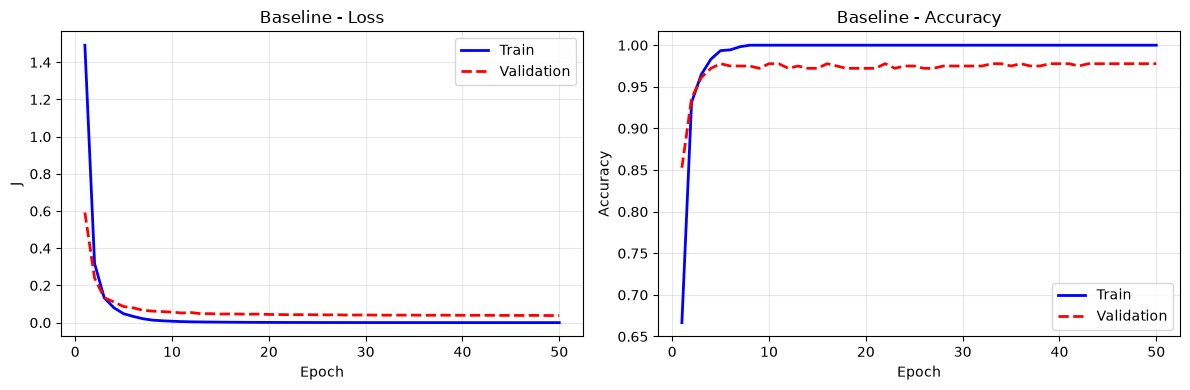

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs_range = range(1, epochs + 1)

axes[0].plot(epochs_range, train_losses_baseline, 'b-', linewidth=2, label='Train')
axes[0].plot(epochs_range, val_losses_baseline, 'r--', linewidth=2, label='Validation')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('J')
axes[0].set_title('Baseline - Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, train_accs_baseline, 'b-', linewidth=2, label='Train')
axes[1].plot(epochs_range, val_accs_baseline, 'r--', linewidth=2, label='Validation')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Baseline - Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Train loss = average over the epoch, while the weights were still changing → at epoch 1 it lies above the validation loss
- Training loss → 0.0001, validation loss levels off near 0.04 from epoch 15 → the later epochs only fit the training set
- Validation accuracy → 0.972–0.978 from epoch 5 on, 0.978 at the end (8 errors in 360)

---
## Step 8. An Improved Model — Build and Train

| Added | What it does | Baseline |
|:---|:---|:---|
| He (Kaiming normal) initialization | normal initial weights, std $\sigma_w$ matched to ReLU | PyTorch default |
| `nn.BatchNorm1d(128)` | standardizes each `nn.Linear` output over the batch (eval mode: running statistics) | none |
| `nn.Dropout(0.3)` | zeroes 30% of units while training | none |
| Weight decay via `weight_decay` | $L_2$ penalty on the weights | 0 |

$$\sigma_w = \sqrt{2 / n_{\text{in}}}, \qquad n_{\text{in}} = \text{inputs of the layer (64 or 128)}$$

- `weight_decay` $= \lambda = 10^{-3}$ → adds $\lambda\mathbf{w}$ to the gradient, i.e. minimizes $J + \tfrac{\lambda}{2}\lVert\mathbf{w}\rVert_2^2$

- **Fixed** → loaders, widths, Adam at $\rho = 0.001$, batch size, epochs, `torch.manual_seed(42)` before construction and before training
- Four changes at once → shows what the **group** is worth, not each member

In [13]:
class MLPImproved(nn.Module):
    def __init__(self, in_features, hidden, out_features):
        super().__init__()
        self.fc1  = nn.Linear(in_features, hidden)
        self.bn1  = nn.BatchNorm1d(hidden)
        self.fc2  = nn.Linear(hidden, hidden)
        self.bn2  = nn.BatchNorm1d(hidden)
        self.fc3  = nn.Linear(hidden, out_features)
        self.relu = nn.ReLU()
        self.drop = nn.Dropout(0.3)
        for layer in [self.fc1, self.fc2, self.fc3]:      # He initialization for every nn.Linear
            nn.init.kaiming_normal_(layer.weight, nonlinearity='relu')

    def forward(self, x):
        h1 = self.drop(self.relu(self.bn1(self.fc1(x))))   # Linear -> BatchNorm -> ReLU -> Dropout
        h2 = self.drop(self.relu(self.bn2(self.fc2(h1))))
        z  = self.fc3(h2)
        return z


torch.manual_seed(42)
model_improved = MLPImproved(64, 128, 10).to(device)

optimizer_improved = torch.optim.Adam(model_improved.parameters(), lr=rho, weight_decay=1e-3)

print(model_improved)
print()
n_params = sum(p.numel() for p in model_improved.parameters())
print(f'Total parameters: {n_params:,}')

MLPImproved(
  (fc1): Linear(in_features=64, out_features=128, bias=True)
  (bn1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc2): Linear(in_features=128, out_features=128, bias=True)
  (bn2): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (fc3): Linear(in_features=128, out_features=10, bias=True)
  (relu): ReLU()
  (drop): Dropout(p=0.3, inplace=False)
)

Total parameters: 26,634


In [14]:
torch.manual_seed(42)   # reseed → both runs start from the same shuffle state
train_losses_improved, train_accs_improved, val_losses_improved, val_accs_improved = train(
    model_improved, train_loader, val_loader, optimizer_improved, epochs=epochs, device=device)

  Epoch   1/50  train_loss=1.9601  val_loss=0.9700  train_acc=0.3565  val_acc=0.8139


  Epoch  10/50  train_loss=0.2531  val_loss=0.1971  train_acc=0.9248  val_acc=0.9583


  Epoch  20/50  train_loss=0.1600  val_loss=0.1005  train_acc=0.9452  val_acc=0.9806


  Epoch  30/50  train_loss=0.1291  val_loss=0.0873  train_acc=0.9610  val_acc=0.9806


  Epoch  40/50  train_loss=0.1160  val_loss=0.0814  train_acc=0.9675  val_acc=0.9806


  Epoch  50/50  train_loss=0.0693  val_loss=0.0716  train_acc=0.9861  val_acc=0.9833


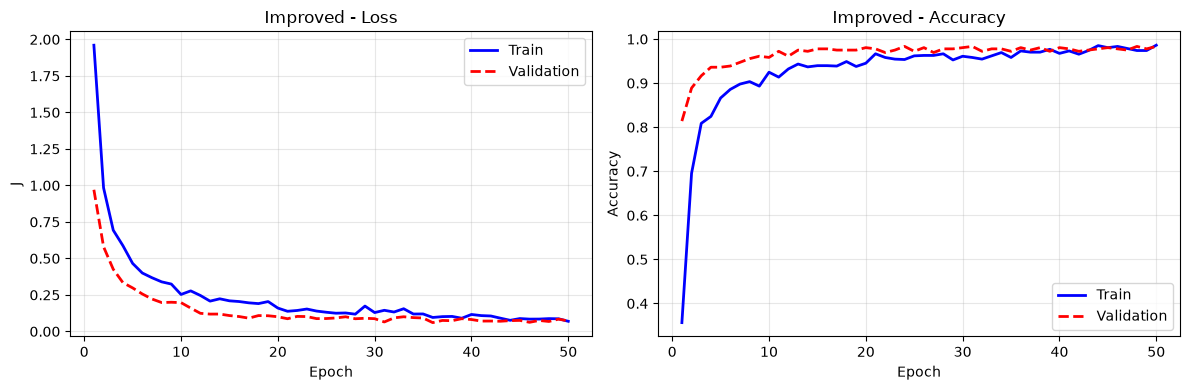

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, train_losses_improved, 'b-', linewidth=2, label='Train')
axes[0].plot(epochs_range, val_losses_improved, 'r--', linewidth=2, label='Validation')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('J')
axes[0].set_title('Improved - Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, train_accs_improved, 'b-', linewidth=2, label='Train')
axes[1].plot(epochs_range, val_accs_improved, 'r--', linewidth=2, label='Validation')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Improved - Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

- Train loss above validation loss for 40 epochs (0.253 vs. 0.197 at epoch 10) → dropout and batch norm act differently in `model.train()` and `model.eval()`; the gap closes by epoch 50 (0.069 vs. 0.072)
- 26,634 parameters, 512 more than the baseline → BatchNorm's scale and shift, $2 \times 128$ per layer

### Optional — the same model as `nn.Sequential`

- One expression instead of a class → the modules run in the order written, no `forward` to write; same layers, same parameter count

In [16]:
model_sequential = nn.Sequential(
    nn.Linear(64, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(128, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(128, 10),
)
for layer in model_sequential:
    if isinstance(layer, nn.Linear):
        nn.init.kaiming_normal_(layer.weight, nonlinearity='relu')

print(model_sequential)
n_params = sum(p.numel() for p in model_sequential.parameters())
print(f'Total parameters: {n_params:,}')

Sequential(
  (0): Linear(in_features=64, out_features=128, bias=True)
  (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): Dropout(p=0.3, inplace=False)
  (4): Linear(in_features=128, out_features=128, bias=True)
  (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (6): ReLU()
  (7): Dropout(p=0.3, inplace=False)
  (8): Linear(in_features=128, out_features=10, bias=True)
)
Total parameters: 26,634


---
## Step 9. Baseline vs. Improved

- Validation curves only → the ones that measure generalization

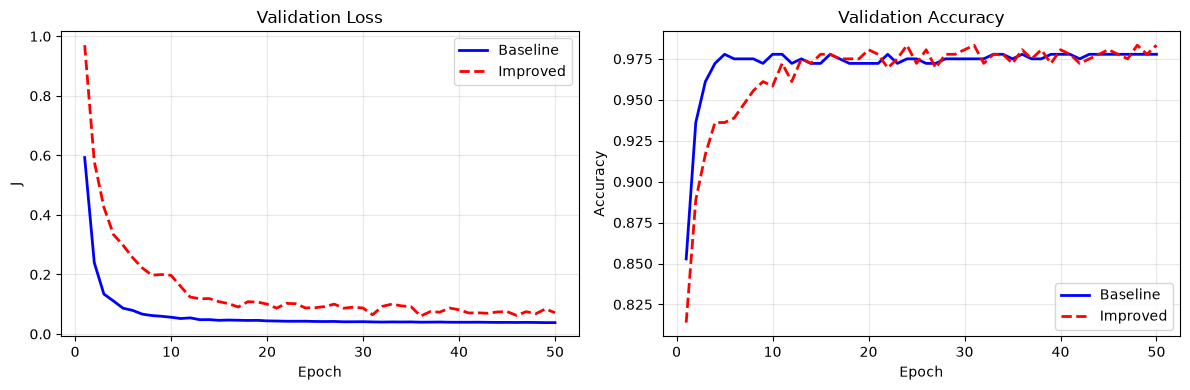

final val_loss - baseline: 0.0383, improved: 0.0716
final val_acc  - baseline: 0.9778, improved: 0.9833


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_range, val_losses_baseline, 'b-', linewidth=2, label='Baseline')
axes[0].plot(epochs_range, val_losses_improved, 'r--', linewidth=2, label='Improved')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('J')
axes[0].set_title('Validation Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, val_accs_baseline, 'b-', linewidth=2, label='Baseline')
axes[1].plot(epochs_range, val_accs_improved, 'r--', linewidth=2, label='Improved')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Validation Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f'final val_loss - baseline: {val_losses_baseline[-1]:.4f}, improved: {val_losses_improved[-1]:.4f}')
print(f'final val_acc  - baseline: {val_accs_baseline[-1]:.4f}, improved: {val_accs_improved[-1]:.4f}')

- Validation loss → the baseline stays lower and ends at 0.038 vs. 0.072; the improved model's loss is noisier and drifts down slowly
- Validation accuracy → the improved model catches up by epoch 15 and ends higher, 0.983 vs. 0.978 — two samples, within the noise

---
## Step 10. Final Test Evaluation

- Training is over, no choice depends on these numbers → read the test set now, once per model

In [18]:
loss_test_baseline, acc_test_baseline, y_pred_baseline = evaluate(model_baseline, test_loader, device)
loss_test_improved, acc_test_improved, y_pred_improved = evaluate(model_improved, test_loader, device)

print(f'Baseline  test_loss={loss_test_baseline:.4f}  test_acc={acc_test_baseline:.4f}')
print(f'Improved  test_loss={loss_test_improved:.4f}  test_acc={acc_test_improved:.4f}')

Baseline  test_loss=0.1227  test_acc=0.9778
Improved  test_loss=0.0688  test_acc=0.9778


- Same accuracy, different loss → cross-entropy also charges for confidence: the softmax probability each model puts on its wrong answers

In [19]:
with torch.no_grad():
    prob_baseline = torch.softmax(model_baseline(X_test_t.to(device)), dim=1).max(dim=1).values.cpu().numpy()
    prob_improved = torch.softmax(model_improved(X_test_t.to(device)), dim=1).max(dim=1).values.cpu().numpy()

wrong_baseline = y_pred_baseline != y_test
wrong_improved = y_pred_improved != y_test
confidence_baseline = prob_baseline[wrong_baseline].mean()
confidence_improved = prob_improved[wrong_improved].mean()

print(f'errors - baseline: {wrong_baseline.sum()}, improved: {wrong_improved.sum()}')
print(f'mean softmax probability on the wrong answers - baseline: {confidence_baseline:.2f}, improved: {confidence_improved:.2f}')

errors - baseline: 8, improved: 8
mean softmax probability on the wrong answers - baseline: 0.84, improved: 0.65


- Both models → 0.978, 8 errors each in 360; one sample = 0.28 percentage points → the test set cannot rank them
- Test loss 0.123 vs. 0.069 → the baseline puts 0.84 on its wrong answers, the improved model 0.65 (dropout and weight decay keep the logits smaller); on validation the order was reversed, 0.038 vs. 0.072 → a few confident mistakes decide the loss, too

---
## Step 11. Where the Errors Are

- Accuracy counts the errors, it does not locate them → look at one model, the improved one, through its `y_pred` from `evaluate`
- First four of its eight misclassified digits → undo the standardization, reshape 64 → $8 \times 8$; then the confusion matrix, whose off-diagonal entries name the digit pairs being confused

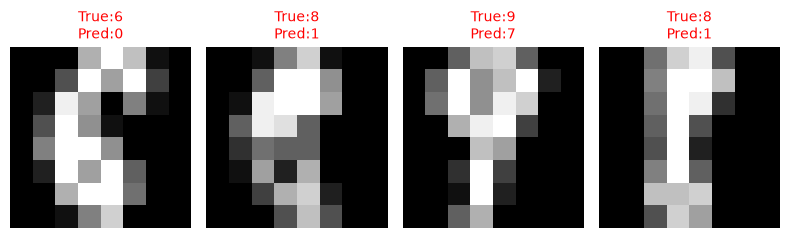

In [20]:
X_test_display = X_test * scaler.scale_ + scaler.mean_     # back to the original 0-16 pixel scale for display
wrong_index = np.where(wrong_improved)[0]

fig, axes = plt.subplots(1, 4, figsize=(8, 2.5))
for i in range(4):
    axes[i].axis('off')
    if i < len(wrong_index):      # with fewer than four errors the remaining panels stay empty
        index = wrong_index[i]
        axes[i].imshow(X_test_display[index].reshape(8, 8), cmap='gray')
        axes[i].set_title(f'True:{y_test[index]}\nPred:{y_pred_improved[index]}', color='red', fontsize=10)
plt.tight_layout()
plt.show()

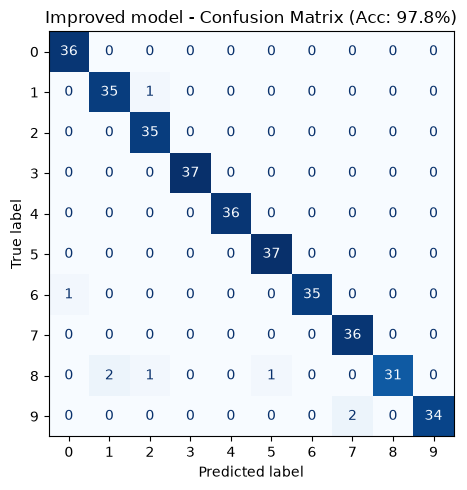

In [21]:
fig, ax = plt.subplots(figsize=(6, 5))
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=confusion_matrix(y_test, y_pred_improved), display_labels=range(10))
display_matrix.plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Improved model - Confusion Matrix (Acc: {acc_test_improved:.1%})')
plt.tight_layout()
plt.show()

- 8 errors in 360 → four are true 8s (read as 1, 1, 2, 5), two 9s read as 7, one 1 as 2, one 6 as 0

---
## Summary

- Validation → read every epoch, used to compare the models; test → read once, after every choice is made
- `train` / `evaluate` name neither model nor dataset → the second model needed no new training code
- The four techniques, as a group → slower to converge, equal test accuracy (0.978); the loss ranks them one way on validation and the other way on test → 360 samples rank them by neither

---
## Exercises

Re-run Steps 3–4 (or the first cell of Step 8) before each run → a fresh model and optimizer.

1. `batch_size = 4`, then `256` — iterations per epoch, run time, loss curve?
2. `torch.optim.SGD(..., lr=rho)` — how many epochs to match Adam's 50-epoch result?
3. The four techniques one at a time — which matters most?
4. Baseline on 10% of the training set — what do the two loss curves do?

In [22]:
# Write your code here